In [ ]:
cd res/

/Users/leo/Documents/github/physics-of-agents/res


In [2]:
# Trajectory archetypes from data/clean_runs.json: individual trajectories
# (per-agent flip classes) and group trajectories (per-society band classes).
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors

from utils import (MODELS, REGIMES, TAU, IND_CLASSES, GRP_CLASSES, load_data,
                   opinions, flip_counts, individual_archetypes, group_archetypes)

runs, banks, P, GCLASS = load_data()

# Compute each run's mean opinion \bar{o}_i
for r in runs:
    # opinions: Computes the mean opinion of each agent over the last 5 rounds of the simulation.
    r["opinions"] = opinions(r)  # (9 rounds, 32 agents), k=5-resample means
print(len(runs), "societies")

9608 societies


In [3]:
matches = [
    (i, r)
    for i, r in enumerate(runs)
    if r.get("statement") == "Student loan debt should be forgiven by the government"
    and r.get("model") == "openai/gpt-oss-safeguard-20b"
]

print("Matches:", len(matches))

for i, r in matches:
    print(i, r.get("model"), r.get("mode"), r.get("statement"))

Matches: 1
4804 openai/gpt-oss-safeguard-20b subjective Student loan debt should be forgiven by the government


In [4]:
r = runs[4804]

print("Statement:", r["statement"])
print("\nPersonas:")
for i, p in enumerate(r.get("personas", [])):
    print(f"Agent {i}: {p}")

print("\nJ:")
for row in r["J"]:
    print(row)

print("\nOpinion history:")
for t, spins in enumerate(r["spins_history"]):
    print(f"Round {t}: {spins}")

Statement: Student loan debt should be forgiven by the government

Personas:

J:
[0, 0, 0, -1, -1, 0, 0, 0, 0, 0, 0, 0, -1, 0, -1, 0, 0, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[-1, 0, 0, 0, 0, 1, -1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, 0, 0, -1, 0, -1, 0, 0, 0, 0]
[-1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 1, 0, 0, 0, -1, 0, 0, 0, -1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, -1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
[0, 0, 0, 0, 0, -1, 1, 0, -1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 1, 0, 0, 0, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0]
[0, 0, 1, 1, 1, 0, 0, 0, 0, 

In [5]:
from pathlib import Path
import json

model = r["model"]
regime = r["mode"]

if "openai/" in model:
    model = model.split("/")[-1]

manifest_path = (
    Path("../data/models")
    / model
    / f"{regime}_energy"
    / "manifest.json"
)

print(manifest_path)
print(manifest_path.exists())

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

print(manifest.keys())

reps = manifest.get("replicas", {}).values()

example_question = next(iter(reps))

reps

../data/models/gpt-oss-safeguard-20b/subjective_energy/manifest.json
True
dict_keys(['meta', 'replicas'])


dict_values([{'qid': 'political_stance_0', 'split': 'train', 'question': 'Student loan debt should be forgiven by the government', 'graph_id': 'J0', 'graph_seen': True, 'repeat': 0, 'num_edges': 112}, {'qid': 'political_stance_156', 'split': 'test', 'question': 'Financial transaction taxes would reduce market volatility', 'graph_id': 'J0', 'graph_seen': True, 'repeat': 0, 'num_edges': 112}])

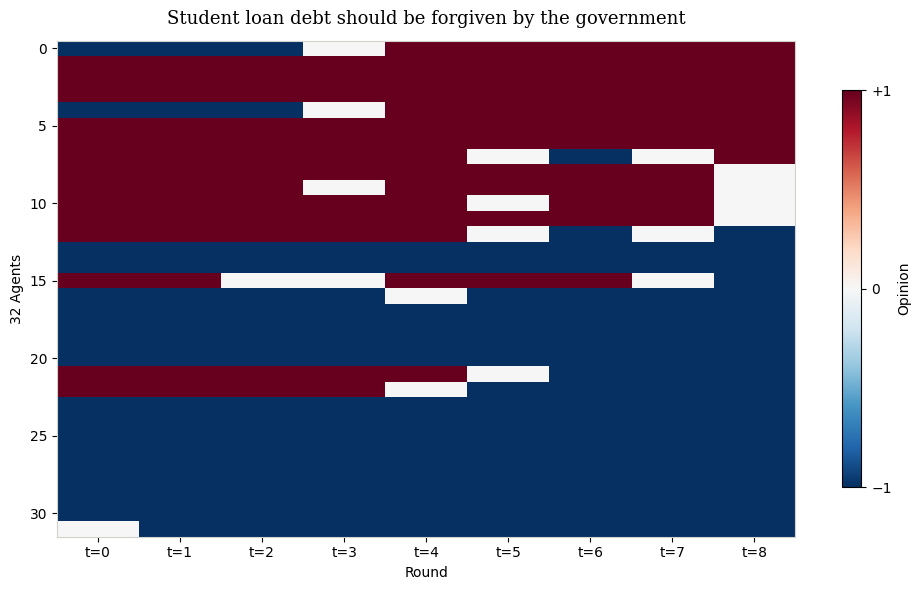

In [6]:
import numpy as np
import matplotlib.pyplot as plt

opinions = np.asarray(r["spins_history"])

# opinions shape: (rounds, agents)
T, N = opinions.shape

fig, ax = plt.subplots(figsize=(10, 6))

# Sort agents by their final opinion
order = np.argsort(-opinions[-1])

# Agents x rounds
data = opinions.T[order]

im = ax.imshow(
    data,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

# X axis
ax.set_xticks(
    range(T),
    [f"t={t}" for t in range(T)]
)

# Y axis
# ax.set_yticks(
#     range(N),
#     [f"Agent {i}" for i in order]
# )

ax.set_xlabel("Round")
ax.set_ylabel(f"{N} Agents")

ax.set_title(
    r["statement"],
    fontsize=13,
    family="serif",
    pad=12
)

# Add values inside cells
for i in range(N):
    for t in range(T):
        value = data[i, t]

        if value > 0:
            text_color = "white"
        else:
            text_color = "black"

        # ax.text(
        #     t,
        #     i,
        #     f"{value:+.0f}",
        #     ha="center",
        #     va="center",
        #     fontsize=9,
        #     color=text_color
        # )

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Opinion")

cbar.set_ticks([-1, 0, 1])
cbar.set_ticklabels(["−1", "0", "+1"])

# Borders
for s in ax.spines.values():
    s.set_color("#d2d2cc")

plt.tight_layout()
plt.show()

In [11]:
pwd

'/Users/leo/Documents/github/physics-of-agents/res'

In [10]:
# Retrieve messages from example run 

import json
from pathlib import Path

def get_messages(model, regime, qid, graph, rep, data_dir="../data/models"):
    file = (
        Path(data_dir)
        / model
        / f"{regime}_energy"
        / f"{qid}__{graph}__rep{rep:02d}.json"
    )

    print(file)

    with open(file, "r", encoding="utf-8") as f:
        raw = json.load(f)

    return raw.get("messages_history", [])

In [12]:
qid = example_question["qid"]
graph = example_question["graph_id"]

if "/" in r["model"]:
    r["model"] = r["model"].split("/")[-1]

messages = get_messages(
    model=r["model"],
    regime=r["mode"],
    qid=example_question["qid"],
    graph=example_question["graph_id"],
    rep=example_question["repeat"]
)

print("\nMessages:")

for t, round_messages in enumerate(messages):
    print(f"\n--- Round {t} ---")

    for sender_receiver, message in round_messages.items():
        print(sender_receiver, ":", message)

../data/models/gpt-oss-safeguard-20b/subjective_energy/political_stance_0__J0__rep00.json

Messages:

--- Round 0 ---
0,3 : I agree that student loan debt should be forgiven because it frees people—especially those from under‑served communities—from a crippling financial burden that limits their ability to buy homes, start businesses, and invest in sustainable living. Cutting
0,4 : I agree that student loan debt should be forgiven because it frees people—especially those from under‑served communities—from a crippling financial burden that limits their ability to buy homes, start businesses, and invest in sustainable living. Cutting
0,12 : I agree that student loan debt should be forgiven because it frees people—especially those from under‑served communities—from a crippling financial burden that limits their ability to buy homes, start businesses, and invest in sustainable living. Cutting
0,14 : I agree that student loan debt should be forgiven because it frees people—especially those 

gemma 26b

In [18]:
matches = [
    (i, r)
    for i, r in enumerate(runs)
    if r.get("statement") == "Student loan debt should be forgiven by the government"
    and r.get("model") == "gemma-4-26b-a4b-it"
]

print("Matches:", len(matches))

for i, r in matches:
    print(i, r.get("model"), r.get("mode"), r.get("statement"))

Matches: 1
2402 gemma-4-26b-a4b-it subjective Student loan debt should be forgiven by the government


In [19]:
gemma_r = runs[2402]

print("Statement:", gemma_r["statement"])
print("\nPersonas:")
for i, p in enumerate(gemma_r.get("personas", [])):
    print(f"Agent {i}: {p}")

print("\nJ:")
for row in gemma_r["J"]:
    print(row)

print("\nOpinion history:")
for t, spins in enumerate(gemma_r["spins_history"]):
    print(f"Round {t}: {spins}")

Statement: Student loan debt should be forgiven by the government

Personas:

J:
[0, 0, 0, -1]
[0, 0, -1, 0]
[0, -1, 0, 1]
[-1, 0, 1, 0]

Opinion history:
Round 0: [1, 1, 1, -1]
Round 1: [1, -1, -1, 1]
Round 2: [-1, 1, 1, -1]


In [20]:
# from pathlib import Path
# import json

model = gemma_r["model"]
regime = gemma_r["mode"]

manifest_path = (
    Path("../data/models")
    / model
    / f"{regime}_energy"
    / "manifest.json"
)

print(manifest_path)
print(manifest_path.exists())

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

print(manifest.keys())

reps = manifest.get("replicas", {}).values()

example_question = next(iter(reps))

reps

../data/models/gemma-4-26b-a4b-it/subjective_energy/manifest.json
True
dict_keys(['meta', 'replicas'])


dict_values([{'qid': 'political_stance_0', 'split': 'train', 'question': 'Student loan debt should be forgiven by the government', 'graph_id': 'J0', 'graph_seen': True, 'repeat': 0, 'num_edges': 6}, {'qid': 'political_stance_156', 'split': 'test', 'question': 'Financial transaction taxes would reduce market volatility', 'graph_id': 'J0', 'graph_seen': True, 'repeat': 0, 'num_edges': 6}])

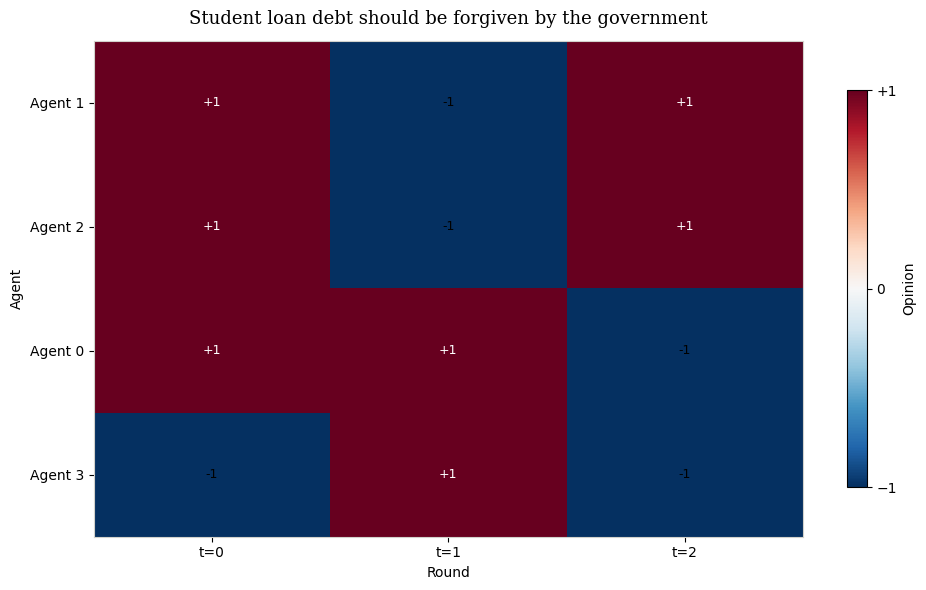

In [21]:
opinions = np.asarray(gemma_r["spins_history"])

# opinions shape: (rounds, agents)
T, N = opinions.shape

fig, ax = plt.subplots(figsize=(10, 6))

# Sort agents by their final opinion
order = np.argsort(-opinions[-1])

# Agents x rounds
data = opinions.T[order]

im = ax.imshow(
    data,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    aspect="auto",
    interpolation="nearest"
)

# X axis
ax.set_xticks(
    range(T),
    [f"t={t}" for t in range(T)]
)

# Y axis
ax.set_yticks(
    range(N),
    [f"Agent {i}" for i in order]
)

ax.set_xlabel("Round")
ax.set_ylabel("Agent")

ax.set_title(
    r["statement"],
    fontsize=13,
    family="serif",
    pad=12
)

# Add values inside cells
for i in range(N):
    for t in range(T):
        value = data[i, t]

        if value > 0:
            text_color = "white"
        else:
            text_color = "black"

        ax.text(
            t,
            i,
            f"{value:+.0f}",
            ha="center",
            va="center",
            fontsize=9,
            color=text_color
        )

# Colorbar
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label("Opinion")

cbar.set_ticks([-1, 0, 1])
cbar.set_ticklabels(["−1", "0", "+1"])

# Borders
for s in ax.spines.values():
    s.set_color("#d2d2cc")

plt.tight_layout()
plt.show()

In [22]:
qid = example_question["qid"]
graph = example_question["graph_id"]

messages = get_messages(
    model=r["model"],
    regime=r["mode"],
    qid=example_question["qid"],
    graph=example_question["graph_id"],
    rep=example_question["repeat"]
)

print("\nMessages:")

for t, round_messages in enumerate(messages):
    print(f"\n--- Round {t} ---")

    for sender_receiver, message in round_messages.items():
        print(sender_receiver, ":", message)

../data/models/gemma-4-26b-a4b-it/subjective_energy/political_stance_0__J0__rep00.json

Messages:

--- Round 0 ---
0,3 : I really think student loan debt should be forgiven because it's just so unfair how it keeps people from being able to build a stable life. It would relieve so much of the constant stress and give everyone a fair chance to move forward.
1,2 : It’s so hard to feel like I have my life together when this debt is constantly making it impossible to stay organized and financially stable. I think forgiveness would be the fairest way to help us all finally get on a predictable track.
2,1 : It feels like unnecessary nonsense to keep people held back by massive debt just for trying to get an education. Forgiving it would be a much simpler way to level the playing field for everyone.
2,3 : It feels like unnecessary nonsense to keep people held back by massive debt just for trying to get an education. Forgiving it would be a much simpler way to level the playing field for everyo